# Hybrid 06 · Nested tuning and the primary model comparison

**Objective:** tune the tabular and hybrid Random Forests without access to the held-out donors and compare them with the fitted ECD tree; apply the application selection rule fixed before the run.

**Derived from:** `notebooks/images/13_nested_tuning_model_selection.ipynb` (planned: protocol written before execution, not committed separately).
**Cohort / design:** outer = the 25 V2 folds restricted to K3 (training) and evaluated on K4 (470 tissues); inner = 3-fold donor-grouped CV inside each outer training fold.

**Runtime and reproduction:** the full run takes ≈72 min. By default this notebook re-runs **one complete outer fold** live (≈3 min) and checks it against the saved results, then loads the saved 25-fold scores (`nested_tuning_fold_scores.csv`, written by notebook 13) and recomputes every statistic from them. Set `RUN_FULL_NESTED_CV = True` to recompute all 25 folds; results stay in memory and no file is written.

In [1]:
RUN_FULL_NESTED_CV = False
CHECK_FOLD = (0, 0)  # (repeat, fold) re-run live when RUN_FULL_NESTED_CV is False

Set up paths, the primary cohort and the feature matrix.

In [2]:
import sys
import time
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
k3, folds, has_ecd = cs.primary_cohort()
X, y, donors = cs.feature_matrix(k3)
SCORES_PATH = ms.PROCESSED_DIR / "nested_tuning_fold_scores.csv"
SELECTIONS_PATH = ms.PROCESSED_DIR / "nested_tuning_selections.csv"
for path in [ms.DATA_PATH, ms.DONOR_FOLDS_PATH, cs.EMBEDDING_PATH, SCORES_PATH, SELECTIONS_PATH]:
    print(f"{path.name}: sha256 {cs.sha256(path)}…")

cleaned_grading_dataset.xlsx: sha256 0ce9b384a51a4c47…
donor_grouped_folds.csv: sha256 755280ff9d7bd388…
resnet50_imagenet_fullres.npz: sha256 883d4a1723a17be7…
nested_tuning_fold_scores.csv: sha256 ad9536db279af708…
nested_tuning_selections.csv: sha256 7ff3077bc130fa81…


## 1. Search spaces (fixed before the run)

Tabular: 24 forest settings. Hybrid: the same 24 × PCA {8, 16, 32} = 72. The grid order is the tie-break order (fewer PCA components, larger leaf, depth 15 before None, "sqrt" before 0.3, balanced before None). The ECD tree is not tuned.

In [3]:
TAB_GRID = [
    {"min_samples_leaf": leaf, "max_depth": depth, "max_features": features, "class_weight": weight}
    for leaf in [5, 2, 1]
    for depth in [15, None]
    for features in ["sqrt", 0.3]
    for weight in ["balanced", None]
]
PCA_GRID = [8, 16, 32]
ARMS = {"Tuned tabular": [None], "Tuned hybrid": PCA_GRID}
MODELS = ["ECD tree", "Tuned tabular", "Tuned hybrid"]
print(len(TAB_GRID), "forest settings ×", PCA_GRID, "PCA options")

24 forest settings × [8, 16, 32] PCA options


## 2. Nested tuning procedure (code from notebook 13)

Inner selection: mean macro F1 over 3 donor-grouped inner folds of the outer **training** fold; preprocessing (imputation, scaling, encoding, PCA) is fitted on inner-training data only. The selected setting is then refitted on the whole outer training fold.

In [4]:
def make_forest(setting):
    return RandomForestClassifier(n_estimators=300, random_state=cs.SEED, n_jobs=-1, **setting)


def tune(rows, pca_options):
    """Select a setting by 3-fold donor-grouped inner CV on `rows` (positions in the cohort)."""
    candidates = [(k, s) for k in pca_options for s in TAB_GRID]
    scores = np.zeros((3, len(candidates)))
    splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=cs.SEED)
    for i, (inner_train, inner_val) in enumerate(splitter.split(rows, y[rows], groups=donors[rows])):
        tr, va = rows[inner_train], rows[inner_val]
        assert set(y[va]) == set(cs.CLASSES), "An inner validation fold lacks a grade"
        assert set(donors[tr]).isdisjoint(donors[va]), "Inner donor leak"
        for k in pca_options:
            pre = cs.preprocessor(k).fit(X.iloc[tr], y[tr])
            Z_tr, Z_va = pre.transform(X.iloc[tr]), pre.transform(X.iloc[va])
            for j, (kk, setting) in enumerate(candidates):
                if kk == k:
                    scores[i, j] = cs.macro_f1(y[va], make_forest(setting).fit(Z_tr, y[tr]).predict(Z_va))
    mean_scores = scores.mean(axis=0)
    best = int(np.argmax(mean_scores))  # first maximum = tie-break order
    return candidates[best], mean_scores[best]


def fit_selected(rows, choice):
    k, setting = choice
    return Pipeline([("features", cs.preprocessor(k)), ("classifier", make_forest(setting))]).fit(X.iloc[rows], y[rows])


def run_outer_fold(repeat, fold, train, test):
    """ECD tree + tuned tabular + tuned hybrid for one outer fold, evaluated on its K4 tissues."""
    assert set(donors[train]).isdisjoint(donors[test]), "Outer donor leak"
    eval_test, train_ecd = test[has_ecd[test]], train[has_ecd[train]]
    predictions = {"ECD tree": cs.ecd_tree().fit(X.iloc[train_ecd], y[train_ecd]).predict(X.iloc[eval_test])}
    selections = []
    for arm, pca_options in ARMS.items():
        choice, inner_score = tune(train, pca_options)
        predictions[arm] = fit_selected(train, choice).predict(X.iloc[eval_test])
        selections.append({"Arm": arm, "Repeat": repeat, "Fold": fold, "PCA": choice[0], **choice[1], "Inner macro F1": inner_score})
    scores = [{"Model": m, "Repeat": repeat, "Fold": fold, "N": len(eval_test), **{k: fn(y[eval_test], p) for k, fn in cs.METRICS.items()}}
              for m, p in predictions.items()]
    return scores, selections, predictions, eval_test

## 3. Run the outer cross-validation

Either all 25 outer folds, or the check fold only, compared with the saved notebook 13 results (metrics to 1e-9, and the same selected settings).

In [5]:
jobs = [(r, f, tr, te) for r in range(ms.N_REPEATS) for f, (tr, te) in enumerate(ms.iter_donor_folds(folds, k3["Tissue_ID"], r))]
N_TRAIN, N_TEST = np.mean([(len(tr), len(te)) for _, _, tr, te in jobs], axis=0)
saved_scores = pd.read_csv(SCORES_PATH)
saved_selections = pd.read_csv(SELECTIONS_PATH)

start, rows, selection_rows = time.time(), [], []
for repeat, fold, train, test in jobs:
    if RUN_FULL_NESTED_CV or (repeat, fold) == CHECK_FOLD:
        scores, selections, _, _ = run_outer_fold(repeat, fold, train, test)
        rows += scores
        selection_rows += selections
        print(f"Repeat {repeat} fold {fold} done — {(time.time() - start) / 60:.1f} min elapsed")
live_scores, live_selections = pd.DataFrame(rows), pd.DataFrame(selection_rows)

key = ["Model", "Repeat", "Fold"]
a = live_scores.set_index(key)[list(cs.METRICS)].sort_index()
b = saved_scores.set_index(key).loc[a.index, list(cs.METRICS)]
print(f"Live folds vs notebook 13: max absolute metric difference {(a - b).abs().to_numpy().max():.1e}")
assert (a - b).abs().to_numpy().max() < 1e-9

setting_columns = ["PCA", "min_samples_leaf", "max_depth", "max_features", "class_weight"]
def as_text(frame):
    return frame.set_index(["Arm", "Repeat", "Fold"])[setting_columns].astype(object).map(lambda v: "None" if pd.isna(v) else str(float(v)) if not isinstance(v, str) else v)
same = as_text(live_selections).equals(as_text(saved_selections).loc[as_text(live_selections).index])
print("Selected settings equal notebook 13:", same)
assert same

fold_scores = live_scores if RUN_FULL_NESTED_CV else saved_scores
selections = live_selections if RUN_FULL_NESTED_CV else saved_selections
print("Source of the 25-fold results:", "recomputed in this session" if RUN_FULL_NESTED_CV else f"{SCORES_PATH.name} (verified on fold {CHECK_FOLD})")

Repeat 0 fold 0 done — 2.9 min elapsed
Live folds vs notebook 13: max absolute metric difference 0.0e+00
Selected settings equal notebook 13: True
Source of the 25-fold results: nested_tuning_fold_scores.csv (verified on fold (0, 0))


## 4. Results on the 470 K4 tissues (fold-level mean ± SD over 25 folds)

In [6]:
cs.summarise(fold_scores, MODELS, cs.METRICS)

,Macro F1,Balanced accuracy,Accuracy,Recall B
ECD tree,0.796 ± 0.038,0.768 ± 0.043,0.804 ± 0.031,0.790 ± 0.117
Tuned tabular,0.805 ± 0.034,0.781 ± 0.037,0.809 ± 0.030,0.793 ± 0.115
Tuned hybrid,0.793 ± 0.047,0.775 ± 0.050,0.797 ± 0.040,0.789 ± 0.130


Primary comparisons T1–T3 (macro F1, Holm across the three; CIs not multiplicity-adjusted), recomputed from the fold scores and checked against `nested_tuning_results.csv`.

In [7]:
COMPARISONS = {"T1": ("Tuned hybrid", "ECD tree"), "T2": ("Tuned tabular", "ECD tree"), "T3": ("Tuned hybrid", "Tuned tabular")}
results = cs.paired_comparisons(fold_scores, COMPARISONS, cs.METRICS, N_TRAIN, N_TEST)
saved_results = pd.read_csv(ms.PROCESSED_DIR / "nested_tuning_results.csv")
check = results.merge(saved_results, on=["ID", "Metric"], suffixes=("", " saved"))
print("Max difference from notebook 13's saved comparisons:",
      f"{max((check[c] - check[c + ' saved']).abs().max() for c in ['Difference', 'CI low', 'CI high', 'p']):.1e}")
primary = results[results["Metric"] == "Macro F1"]
primary[["ID", "Comparison", "Model", "Baseline", "Difference", "CI low", "CI high", "p", "p (Holm)", "Folds improved"]].round(4)

Max difference from notebook 13's saved comparisons: 1.1e-16


,ID,Comparison,Model,Baseline,Difference,CI low,CI high,p,p (Holm),Folds improved
0,T1,Tuned hybrid − ECD tree,0.7934,0.7958,-0.0025,-0.0341,0.0291,0.8730,1.0,11/25
4,T2,Tuned tabular − ECD tree,0.8049,0.7958,0.0091,-0.0102,0.0284,0.3421,1.0,18/25
8,T3,Tuned hybrid − Tuned tabular,0.7934,0.8049,-0.0115,-0.0448,0.0217,0.4811,1.0,8/25


The three macro F1 differences with their corrected 95% CIs: every interval includes zero.

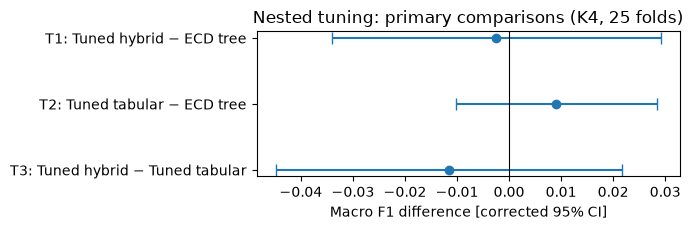

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.4))
for i, (_, row) in enumerate(primary.iterrows()):
    ax.errorbar(row["Difference"], i, xerr=[[row["Difference"] - row["CI low"]], [row["CI high"] - row["Difference"]]],
                fmt="o", capsize=4, color="tab:blue")
ax.axvline(0, color="black", lw=0.8)
ax.set(yticks=range(len(primary)), yticklabels=[f"{r['ID']}: {r['Comparison']}" for _, r in primary.iterrows()],
       xlabel="Macro F1 difference [corrected 95% CI]", title="Nested tuning: primary comparisons (K4, 25 folds)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Secondary metrics (unadjusted).

In [9]:
results[results["Metric"] != "Macro F1"][["ID", "Metric", "Model", "Baseline", "Difference", "CI low", "CI high", "p"]].round(4)

,ID,Metric,Model,Baseline,Difference,CI low,CI high,p
1,T1,Balanced accuracy,0.7750,0.7680,0.0070,-0.0223,0.0363,0.6256
2,T1,Accuracy,0.7971,0.8044,-0.0073,-0.0364,0.0218,0.6103
3,T1,Recall B,0.7891,0.7901,-0.0010,-0.0418,0.0398,0.9612
5,T2,Balanced accuracy,0.7811,0.7680,0.0131,-0.0049,0.0311,0.1474
6,T2,Accuracy,0.8086,0.8044,0.0042,-0.0137,0.0220,0.6345
7,T2,Recall B,0.7931,0.7901,0.0031,-0.0140,0.0202,0.7136
9,T3,Balanced accuracy,0.7750,0.7811,-0.0060,-0.0367,0.0246,0.6875
10,T3,Accuracy,0.7971,0.8086,-0.0114,-0.0448,0.0219,0.4857
11,T3,Recall B,0.7891,0.7931,-0.0040,-0.0407,0.0326,0.8214


Per-grade precision and recall pooled over repeats. Notebook 13 did not save its predictions; these come from notebook 14, which refitted notebook 13's per-fold selections. First confirm those predictions reproduce notebook 13's fold scores.

In [10]:
oof = pd.read_csv(ms.PROCESSED_DIR / "model_family_oof_predictions.csv")
NAMES = {"ECD tree": "ECD tree", "Tuned tabular": "Tuned RF tabular", "Tuned hybrid": "Tuned RF hybrid"}
fold_of = folds.set_index("Tissue_ID")
oof["Fold"] = [fold_of.at[t, f"Fold_r{r}"] for t, r in zip(oof["Tissue_ID"], oof["Repeat"])]
rebuilt = pd.DataFrame([{"Model": m, "Repeat": r, "Fold": f, **{k: fn(g["Actual"], g[col]) for k, fn in cs.METRICS.items()}}
                        for m, col in NAMES.items() for (r, f), g in oof.groupby(["Repeat", "Fold"])])
diff = (rebuilt.set_index(key).sort_index()[list(cs.METRICS)] - saved_scores.set_index(key).sort_index()[list(cs.METRICS)]).abs().to_numpy().max()
print(f"Notebook 14 predictions vs notebook 13 fold scores: max difference {diff:.1e}")
cs.per_grade(oof["Actual"], {m: oof[col] for m, col in NAMES.items()}).round(3)

Notebook 14 predictions vs notebook 13 fold scores: max difference 5.6e-17


ECD tree        Tuned tabular        Tuned hybrid       
   Precision Recall     Precision Recall    Precision Recall
A+     0.748  0.988         0.779  0.943        0.788  0.906
A      0.884  0.528         0.805  0.609        0.761  0.635
B      1.000  0.791         0.978  0.794        0.936  0.791

Selected settings across the 25 outer folds, counting `None` values (notebook 13's printed table dropped them; corrected after the run).

In [11]:
for arm in ARMS:
    counts = selections[selections["Arm"] == arm][setting_columns].astype(object).fillna("None").astype(str).value_counts()
    print(f"\n{arm}: {len(counts)} distinct settings; max_features chosen: "
          f"{selections.loc[selections['Arm'] == arm, 'max_features'].astype(str).value_counts().to_dict()}")
    print(counts.head(6).rename("Folds").to_string())


Tuned tabular: 7 distinct settings; max_features chosen: {'0.3': 25}
PCA   min_samples_leaf  max_depth  max_features  class_weight
None  5                 15.0       0.3           None            8
      2                 15.0       0.3           None            6
      1                 15.0       0.3           None            4
                        None       0.3           None            4
      5                 15.0       0.3           balanced        1
      2                 None       0.3           None            1

Tuned hybrid: 15 distinct settings; max_features chosen: {'0.3': 25}
PCA   min_samples_leaf  max_depth  max_features  class_weight
32.0  5                 15.0       0.3           balanced        6
      2                 15.0       0.3           balanced        3
      1                 15.0       0.3           None            3
16.0  1                 None       0.3           balanced        2
8.0   1                 15.0       0.3           balanced        1

Tuning gain over the untuned notebook 05 settings (Hybrid 04), per fold (descriptive).

In [12]:
untuned = pd.read_csv(ms.PROCESSED_DIR / "fitted_ecd_fold_scores.csv").pivot_table(index=["Repeat", "Fold"], columns="Model", values="Macro F1")
tuned = fold_scores.pivot_table(index=["Repeat", "Fold"], columns="Model", values="Macro F1")
pd.DataFrame({name: {"Mean gain": (tuned[t] - untuned[name]).mean(), "Folds improved": f"{(tuned[t] > untuned[name]).sum()}/25"}
              for t, name in [("Tuned tabular", "Tabular"), ("Tuned hybrid", "Hybrid")]}).T.round(3)

,Mean gain,Folds improved
Tabular,0.049236,24/25
Hybrid,0.004794,15/25


## 5. Application selection rule (fixed before the run, applied mechanically)

A candidate convincingly outperforms the ECD tree only if its macro F1 difference is > 0 with Holm p < 0.05 **and** its grade B recall difference is ≥ −0.02. If neither does, the ECD tree is selected.

In [13]:
p_holm = primary.set_index("ID")
b_recall = results[results["Metric"] == "Recall B"].set_index("ID")["Difference"]
beats_tree = {arm: bool(p_holm.at[cid, "Difference"] > 0 and p_holm.at[cid, "p (Holm)"] < 0.05 and b_recall[cid] >= -0.02)
              for arm, cid in [("Tuned hybrid", "T1"), ("Tuned tabular", "T2")]}
if not any(beats_tree.values()):
    selected = "ECD tree"
elif sum(beats_tree.values()) == 1:
    selected = next(a for a, ok in beats_tree.items() if ok)
else:
    selected = "Tuned hybrid" if (p_holm.at["T3", "Difference"] > 0 and p_holm.at["T3", "p (Holm)"] < 0.05 and b_recall["T3"] >= -0.02) else "Tuned tabular"
print("Convincingly outperforms the ECD tree:", beats_tree)
print("Selected by the rule:", selected)

Convincingly outperforms the ECD tree: {'Tuned hybrid': False, 'Tuned tabular': False}
Selected by the rule: ECD tree


The selected ECD tree, fitted on all 470 K4 tissues: its cut points and the recorded grades in each ECD band.

In [14]:
ecd_rows = np.flatnonzero(has_ecd)
final_tree = DecisionTreeClassifier(**cs.TREE_PARAMS).fit(X.iloc[ecd_rows][[cs.ECD]], y[ecd_rows])
cuts = sorted(float(t) for t in final_tree.tree_.threshold[final_tree.tree_.feature >= 0])
bands = pd.cut(X.iloc[ecd_rows][cs.ECD], [-np.inf, *cuts, np.inf], labels=[f"≤ {cuts[0]:.0f} → B", f"{cuts[0]:.0f}–{cuts[1]:.0f} → A", f"> {cuts[1]:.0f} → A+"])
print("Cut points:", cuts)
pd.crosstab(bands.reset_index(drop=True).rename("ECD band → tree grade"), pd.Series(y[ecd_rows], name="Recorded grade"))[cs.CLASSES]

Cut points: [2232.0, 2497.0]


Recorded grade,A+,A,B
ECD band → tree grade,,,
≤ 2232 → B,0,0,53
2232–2497 → A,2,84,8
> 2497 → A+,242,75,6


## Interpretation

- Neither tuned model convincingly outperformed the ECD tree: T1 −0.003 [−0.034, +0.029], T2 +0.009 [−0.010, +0.028], T3 −0.012 [−0.045, +0.022], all Holm p = 1.00. Under the pre-set rule, **the ECD tree was selected**.
- Tuning raised the tabular model by ≈0.05 macro F1 but the hybrid by only ≈0.005: the hybrid's earlier edge over tabular (Hybrid 04) came from an under-tuned tabular comparator.
- Every fold chose `max_features = 0.3`, the upper edge of the grid, which motivated Hybrid 08.
- Six grade B tissues have ECD above 2497 and are called A+ by the tree; ECD alone cannot identify them.

**Limitations:** the outer folds had already informed earlier decisions (cohort, comparators, PCA size), so this is a nested analysis on reused folds, not an untouched confirmation. The −0.02 grade B threshold is a project rule, not a clinical one. The application's later choice of the hybrid (Hybrid 09) overrides this rule's outcome by project decision.